# Snapshots of a Quantum Phase Transition

The transverse-field Ising chain, $J=1$, periodic boundaries,
$$H = -J\sum_{i=1}^{L} Z_iZ_{i+1} - h\sum_{i=1}^{L} X_i ,$$
is ferromagnetic for $h<1$ and paramagnetic for $h>1$, with a quantum critical point at $h_c=1$
(2D Ising class, $\beta=1/8$, $\nu=1$).

An experiment does not hand you $\psi$. It measures every spin in the $z$ basis and returns one bit string
$s\in\{\pm1\}^L$ with probability $|\psi(s)|^2$: a **snapshot**. We take thousands of snapshots per $h$, run
PCA on them, and ask whether PCA finds the transition, and what exactly it computed.

Every number PCA produces here has an exact counterpart computed from $\psi$, and each one is compared with it.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from functools import lru_cache
import tfim

CHECKS = []
def check(name, ok, detail=''):
    CHECKS.append((name, bool(ok)))
    print(f"CHECK {name}: {'PASS' if ok else 'FAIL'}   {detail}")

LS = [6, 8, 10, 12, 14]

@lru_cache(maxsize=None)
def gs(L, h):
    # parity-projected exact ground state; h rounded so that grids share the cache
    return tfim.ground_state(L, h)[1]

def exact_p(L, h):
    return tfim.probs(gs(L, round(float(h), 6)))

## What the experiment sees

Top: forty snapshots of an $L=12$ chain at three fields. Rows are shots, columns are sites; white is $s=+1$.
Bottom: $M=5000$ snapshots at each of 39 fields for each $L$, PCA on each set, and the fraction of the variance
carried by the first principal component (points). The lines are the exact $\langle m^2\rangle$ from $|\psi|^2$.
Steps 1 and 3 explain why they agree.

5 sizes x 39 fields: ground states, 5000 snapshots, PCA in 3.0 s


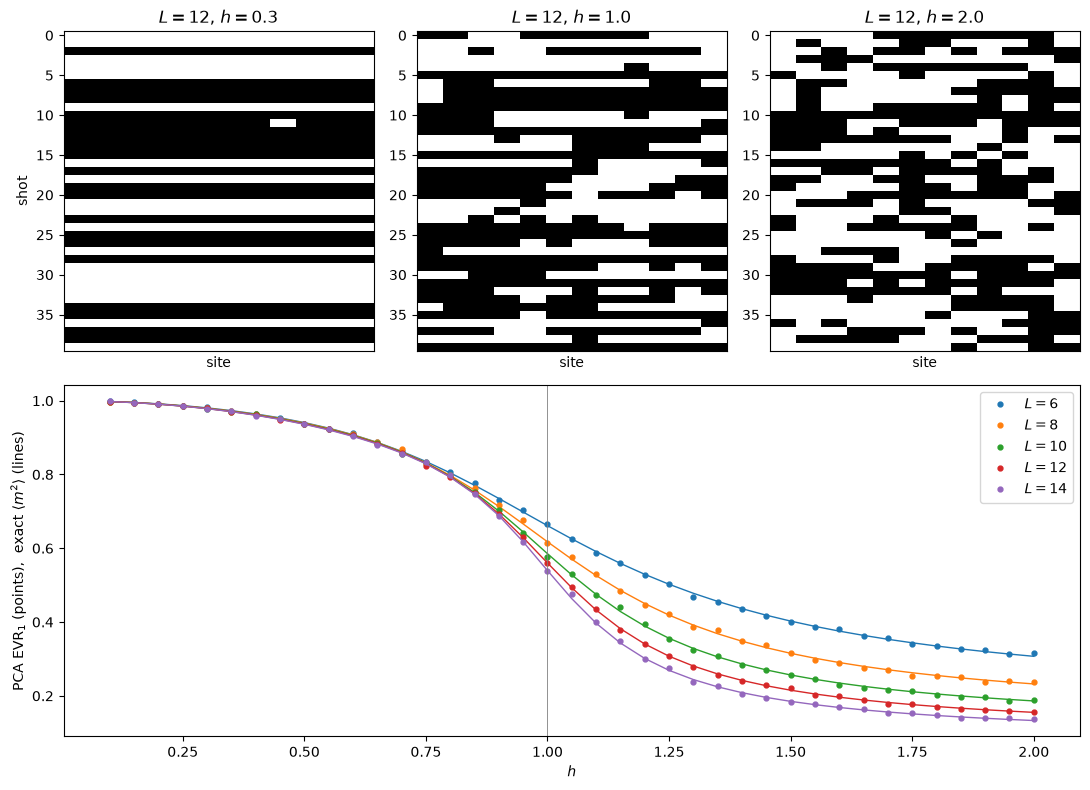

In [2]:
H_GRID = np.round(np.arange(0.1, 2.0001, 0.05), 6)
M_SNAP = 5000
rng = np.random.default_rng(2026)
t0 = time.time()
SNAP, SW = {}, {}
for L in LS:
    rows = []
    for h in H_GRID:
        X = tfim.snapshots(gs(L, h), M_SNAP, rng)
        lam, V, _ = tfim.pca(X)
        m2_exact = tfim.exact_moments(exact_p(L, h))[0]
        m = X.mean(1)
        rows.append((m2_exact, lam[0] / lam.sum(), np.std(m**2) / np.sqrt(M_SNAP),
                     abs(V[:, 0].sum()) / np.sqrt(L)))
        SNAP[L, h] = X
    SW[L] = dict(zip(['m2', 'evr1', 'err', 'overlap'], np.array(rows).T))
print(f'{len(LS)} sizes x {len(H_GRID)} fields: ground states, {M_SNAP} snapshots, PCA in {time.time() - t0:.1f} s')

fig = plt.figure(figsize=(11, 8))
gsp = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
for j, h in enumerate([0.3, 1.0, 2.0]):
    a = fig.add_subplot(gsp[0, j])
    a.imshow(SNAP[12, h][:40], cmap='gray', vmin=-1, vmax=1, aspect='auto', interpolation='nearest')
    a.set_title(f'$L=12$, $h = {h}$'); a.set_xlabel('site'); a.set_xticks([])
    if j == 0: a.set_ylabel('shot')
a = fig.add_subplot(gsp[1, :])
for i, L in enumerate(LS):
    a.plot(H_GRID, SW[L]['m2'], '-', color=f'C{i}', lw=1)
    a.plot(H_GRID, SW[L]['evr1'], 'o', color=f'C{i}', ms=3.5, label=f'$L={L}$')
a.axvline(1, color='gray', lw=0.6)
a.set_xlabel('$h$'); a.set_ylabel(r'PCA EVR$_1$ (points),  exact $\langle m^2\rangle$ (lines)'); a.legend()
plt.tight_layout(); plt.show()

At $h=0.3$ almost every shot is a single color, and both colors appear: the finite-chain ground state is a cat
state $(|\!\uparrow\cdots\uparrow\rangle + |\!\downarrow\cdots\downarrow\rangle)/\sqrt2$ dressed by a few flips. At
$h=1$ there are domains of all sizes. At $h=2$ it is salt-and-pepper. Below, the first principal component
carries almost all the variance in the ordered phase and little of it in the disordered one, with a drop that
sharpens with $L$ near $h=1$, and it sits on the exact $\langle m^2\rangle$ everywhere.

## Step 1 — Exact diagonalization and the benchmark

Basis state $b$ has $s_i = 1-2\,\mathrm{bit}_i(b)$. $Z_iZ_{i+1}$ is diagonal and $X_i$ flips bit $i$, so `tfim.hamiltonian`
builds $H$ as a sparse matrix with a loop over the $L$ sites only, and `eigsh(H, k=1, which='SA')` finds $\psi_0$.

The benchmark is Jordan–Wigner. The ground state is in the even sector of $P=\prod_iX_i$, with
$$E_0 = -\sum_{n=0}^{L-1}\sqrt{1+h^2-2h\cos k_n},\qquad k_n=\frac{(2n+1)\pi}{L},$$
which at $h=1$ is $E_0=-2/\sin(\pi/2L)$.

In [3]:
print(f"{'L':>3} {'h':>5} {'E0 (ED)':>17} {'E0 (free fermions)':>19} {'|diff|':>8}")
worst = 0
for L, h in [(6, 0.3), (8, 0.5), (10, 1.5), (12, 1.0), (12, 0.05), (14, 0.1), (14, 1.0), (14, 2.0)]:
    E = tfim.ground_state(L, h)[0]
    Eff = tfim.free_fermion_energy(L, h)
    worst = max(worst, abs(E - Eff))
    print(f"{L:>3} {h:>5} {E:17.10f} {Eff:19.10f} {abs(E - Eff):8.1e}")
check('E0 from ED matches free fermions', worst < 1e-10, f'max |diff| = {worst:.1e}')
check('free-fermion E0 at h=1 equals -2/sin(pi/2L)',
      all(abs(tfim.free_fermion_energy(L, 1.0) + 2 / np.sin(np.pi / (2 * L))) < 1e-12 for L in LS))
check('reference energies (12, 1) and (8, 0.5)',
      abs(tfim.free_fermion_energy(12, 1.0) + 15.3225951511) < 1e-9
      and abs(tfim.free_fermion_energy(8, 0.5) + 8.5090822351) < 1e-9)

  L     h           E0 (ED)  E0 (free fermions)   |diff|
  6   0.3     -6.1359499853       -6.1359499853  1.8e-15
  8   0.5     -8.5090822351       -8.5090822351  1.8e-15
 10   1.5    -16.7230249139      -16.7230249139  7.1e-15
 12   1.0    -15.3225951511      -15.3225951511  0.0e+00
 12  0.05    -12.0075011726      -12.0075011726  1.6e-14
 14   0.1    -14.0350219299      -14.0350219299  0.0e+00
 14   1.0    -17.8628085408      -17.8628085408  3.6e-15
 14   2.0    -29.7792601325      -29.7792601325  7.1e-15
CHECK E0 from ED matches free fermions: PASS   max |diff| = 1.6e-14
CHECK free-fermion E0 at h=1 equals -2/sin(pi/2L): PASS   
CHECK reference energies (12, 1) and (8, 0.5): PASS   


### The parity trap

For $h<1$ the lowest even and odd states are split by a gap that closes exponentially in $L$. Once it is
below the solver's precision, `eigsh` returns an arbitrary mix of the two: a symmetry-broken state. The
cure is to project, $\psi\leftarrow(\psi+P\psi)/\lVert\psi+P\psi\rVert$. Since $P$ flips every bit, $P\psi$ is `psi[::-1]`.

    h                    <P>      <m>  E0 - E_ff
  0.1    raw eigsh   0.99790   -0.065    3.6e-15
  0.1    projected   1.00000   -0.000   -1.8e-15
 0.05    raw eigsh  -0.24265   -0.970   -1.8e-14
 0.05    projected   1.00000   +0.000   -1.6e-14


CHECK raw eigsh at L=12, h=0.05 falls into the trap: PASS   <P> = -0.243
CHECK <P> = 1 after projection at L=12, h=0.05: PASS   |<P> - 1| = 1.9e-15
CHECK projected E0 still matches free fermions at h=0.05: PASS   


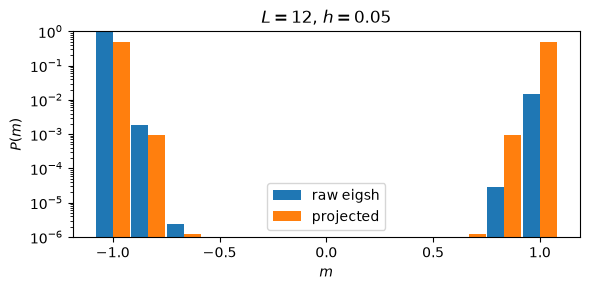

In [4]:
m_L12 = tfim.magnetization(12)
print(f"{'h':>5} {'':>12} {'<P>':>9} {'<m>':>8} {'E0 - E_ff':>10}")
for h in [0.1, 0.05]:
    for proj in [False, True]:
        E, psi = tfim.ground_state(12, h, project=proj)
        print(f"{h:>5} {'projected' if proj else 'raw eigsh':>12} {tfim.parity(psi):9.5f} "
              f"{tfim.probs(psi) @ m_L12:+8.3f} {E - tfim.free_fermion_energy(12, h):10.1e}")
raw = tfim.ground_state(12, 0.05, project=False)[1]
psi_proj = tfim.ground_state(12, 0.05)[1]

check('raw eigsh at L=12, h=0.05 falls into the trap', tfim.parity(raw) < 0.9, f'<P> = {tfim.parity(raw):.3f}')
check('<P> = 1 after projection at L=12, h=0.05', abs(tfim.parity(psi_proj) - 1) < 1e-12,
      f'|<P> - 1| = {abs(tfim.parity(psi_proj) - 1):.1e}')
check('projected E0 still matches free fermions at h=0.05',
      abs(psi_proj @ (tfim.hamiltonian(12, 0.05) @ psi_proj) - tfim.free_fermion_energy(12, 0.05)) < 1e-10)

fig, ax = plt.subplots(figsize=(6, 3))
mv = np.linspace(-1, 1, 13)
for psi, lab, off in [(raw, 'raw eigsh', -0.04), (psi_proj, 'projected', 0.04)]:
    Pm = np.bincount(np.round((m_L12 + 1) * 6).astype(int), weights=tfim.probs(psi), minlength=13)
    ax.bar(mv + off, Pm, width=0.08, label=lab)
ax.set_yscale('log'); ax.set_ylim(1e-6, 1); ax.set_xlabel('$m$'); ax.set_ylabel('$P(m)$')
ax.set_title('$L=12$, $h=0.05$'); ax.legend(); plt.tight_layout(); plt.show()

The energy is right to $10^{-14}$ *either way*: the even–odd splitting at $h=0.05$ is far below double precision,
so the energy check cannot see the trap. Only $\langle P\rangle$ can. The raw state has $\langle m\rangle\approx-0.97$, which is
spontaneous symmetry breaking let in through the solver tolerance. The exact ground state of a finite chain is the
cat, with $P(m)$ symmetric, and its snapshots show both signs of $m$. Every ground state below is projected.

### Exact moments and the correlator

From $|\psi|^2$: $\langle m^2\rangle$, $\langle m^4\rangle$ with $m=\frac1L\sum_is_i$, and $G(r)=\langle Z_0Z_r\rangle$.
These are the exact counterparts for everything that follows. One identity ties them together:
$\sum_r G(r) = L\langle m^2\rangle$.

    h  <m^2> exact    brief
  0.3      0.97871   0.9787
  0.8      0.79361   0.7936
  1.0      0.56011   0.5601
  1.2      0.34053   0.3405
  2.0      0.15519   0.1552
CHECK exact <m^2> at L=12 matches the brief: PASS   
CHECK sum_r G(r) = L <m^2>: PASS   max |diff| = 5.3e-15


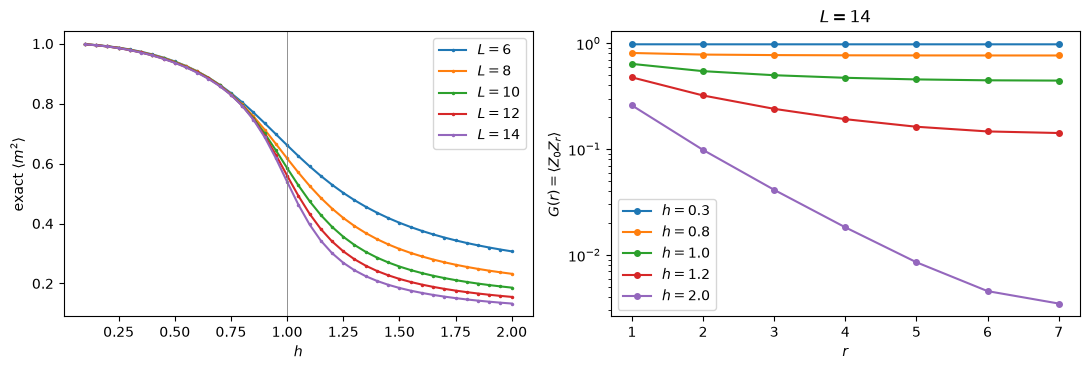

In [5]:
ref_m2 = {0.3: 0.9787, 0.8: 0.7936, 1.0: 0.5601, 1.2: 0.3405, 2.0: 0.1552}
print(f"{'h':>5} {'<m^2> exact':>12} {'brief':>8}")
for h, r in ref_m2.items():
    print(f"{h:>5} {tfim.exact_moments(exact_p(12, h))[0]:12.5f} {r:8.4f}")
check('exact <m^2> at L=12 matches the brief',
      all(abs(tfim.exact_moments(exact_p(12, h))[0] - r) < 5e-5 for h, r in ref_m2.items()))

worst = max(abs(tfim.correlator(exact_p(L, h)).sum() - L * tfim.exact_moments(exact_p(L, h))[0])
            for L in LS for h in [0.3, 1.0, 2.0])
check('sum_r G(r) = L <m^2>', worst < 1e-12, f'max |diff| = {worst:.1e}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for L in LS:
    ax[0].plot(H_GRID, SW[L]['m2'], '.-', ms=3, label=f'$L={L}$')
ax[0].axvline(1, color='gray', lw=0.6); ax[0].set_xlabel('$h$'); ax[0].set_ylabel(r'exact $\langle m^2\rangle$')
ax[0].legend()
r = np.arange(1, 8)
for h in [0.3, 0.8, 1.0, 1.2, 2.0]:
    ax[1].semilogy(r, tfim.correlator(exact_p(14, h))[1:8], 'o-', ms=4, label=f'$h={h}$')
ax[1].set_xlabel('$r$'); ax[1].set_ylabel(r'$G(r)=\langle Z_0Z_r\rangle$'); ax[1].set_title('$L=14$')
ax[1].legend(); plt.tight_layout(); plt.show()

$\langle m^2\rangle$ falls from 1 to small values across $h=1$, and the drop sharpens with $L$. $G(r)$ saturates at a
plateau in the ordered phase (long-range order, $G\to m_0^2$), decays exponentially at $h=2$, and in between
on a 14-site ring it is hard to tell anything apart. That is the finite-size problem Step 5 has to face.

## Step 3 — PCA on the snapshots

Center the snapshots, form the $L\times L$ covariance, diagonalize with `np.linalg.eigh` (`tfim.pca`, five lines,
as on the manual day).

**Prediction, before running it.** The projected ground state has $\langle Z_i\rangle=0$ and $Z_i^2=1$, so
$\mathrm{Tr}\,C=L$. If PC1 is the uniform vector $u=(1,\dots,1)/\sqrt L$, its eigenvalue is
$u^TCu=\frac1L\sum_{ij}\langle Z_iZ_j\rangle = L\langle m^2\rangle$, hence
$$\mathrm{EVR}_1 = \langle m^2\rangle .$$
It should go to 1 as $h\to0$ and to $1/L$ as $h\to\infty$, where $C\to I$. The statistical error on EVR₁ is then
that of a mean of $M$ samples of $m^2$, $\sigma=\mathrm{std}(m^2)/\sqrt M$, and that is what each point is compared with.

In [6]:
print(f"L = 12, M = {M_SNAP}")
print(f"{'h':>5} {'exact <m^2>':>12} {'PCA EVR1':>9} {'sigma':>7} {'z':>6} {'|PC1.u|':>8}")
for h in [0.3, 0.8, 1.0, 1.2, 2.0]:
    i = np.searchsorted(H_GRID, h)
    s = {k: v[i] for k, v in SW[12].items()}
    print(f"{h:>5} {s['m2']:12.4f} {s['evr1']:9.4f} {s['err']:7.4f} {(s['evr1'] - s['m2']) / s['err']:+6.2f} {s['overlap']:8.4f}")

z = np.concatenate([(SW[L]['evr1'] - SW[L]['m2']) / SW[L]['err'] for L in LS])
hz = np.tile(H_GRID, len(LS))
n = len(z)
for name, sel in [('all fields', hz > 0), ('h <= 1.2', hz <= 1.2), ('h > 1.2', hz > 1.2)]:
    print(f"{name:>11}: {sel.sum():3d} points, mean z = {z[sel].mean():+.2f}, chi2/dof = {np.mean(z[sel]**2):.2f}")
check('EVR1 = exact <m^2> within Monte Carlo error over the whole sweep',
      abs(z.mean()) < 3 / np.sqrt(n) and np.mean(z**2) < 1 + 3 * np.sqrt(2 / n) and np.abs(z).max() < 4,
      f'{n} points, chi2/dof = {np.mean(z**2):.2f}, max |z| = {np.abs(z).max():.2f}')
ov = min(SW[L]['overlap'][H_GRID <= 1.2].min() for L in LS)
check('PC1 is the uniform vector for h <= 1.2 at every L', ov > 0.999, f'min |PC1.u| = {ov:.5f}')
lam = tfim.pca(SNAP[12, 2.0])[0]
lam_ex = tfim.pca_cov(tfim.exact_cov(exact_p(12, 2.0)))[0]
print(f"\nL=12, h=2: top PCA eigenvalues {np.round(lam[:3], 3)},  exact {np.round(lam_ex[:3], 3)}")

L = 12, M = 5000
    h  exact <m^2>  PCA EVR1   sigma      z  |PC1.u|
  0.3       0.9787    0.9794  0.0011  +0.63   1.0000
  0.8       0.7936    0.7923  0.0037  -0.34   1.0000
  1.0       0.5601    0.5591  0.0049  -0.21   0.9999
  1.2       0.3405    0.3398  0.0045  -0.16   0.9997
  2.0       0.1552    0.1575  0.0027  +0.85   0.9985
 all fields: 195 points, mean z = +0.06, chi2/dof = 0.84
   h <= 1.2: 115 points, mean z = +0.14, chi2/dof = 0.86
    h > 1.2:  80 points, mean z = -0.07, chi2/dof = 0.82
CHECK EVR1 = exact <m^2> within Monte Carlo error over the whole sweep: PASS   195 points, chi2/dof = 0.84, max |z| = 2.78
CHECK PC1 is the uniform vector for h <= 1.2 at every L: PASS   min |PC1.u| = 0.99967

L=12, h=2: top PCA eigenvalues [1.89  1.532 1.441],  exact [1.862 1.503 1.503]


The prediction holds, and the agreement is at the level of the shot noise, not of a tolerance: the $z$-scores
have $\chi^2/\text{dof}$ near 1 on both sides of the transition. The overlap $|\mathrm{PC1}\cdot u|$ is 0.9997 or better up
to $h=1.2$ and only slips at large $h$. At $L=12$, $h=2$ the exact top eigenvalue is 1.86 and the next two are a
degenerate pair at 1.50. Sampling noise in the covariance, about $\sqrt{\lambda_1\lambda_2/M}\approx0.02$, mixes PC1
with its neighbors by an angle of roughly noise/gap $\approx0.02/0.36$, which takes a few parts in $10^3$ off the
overlap. The smaller the gap, the less PCA can say which direction is "first", and a shrinking gap is itself the
sign that the order is gone.

### Two peaks or one

Project each snapshot on PC1 and divide by $\sqrt L$. With PC1 $=u$ this is $m$, up to sign and the tiny centering.
Its histogram has two peaks in the ordered phase and one in the disordered phase.

CHECK PC1 histograms match the exact P(m) (Pearson chi^2): PASS   chi2 = 63.3 for 55 dof

  L  snapshots: first one-peak h   exact
  6                         1.45  1.4139
  8                         1.30  1.2987
 10                         1.30  1.2334


 12                         1.20  1.1914


 14                         1.25  1.1625


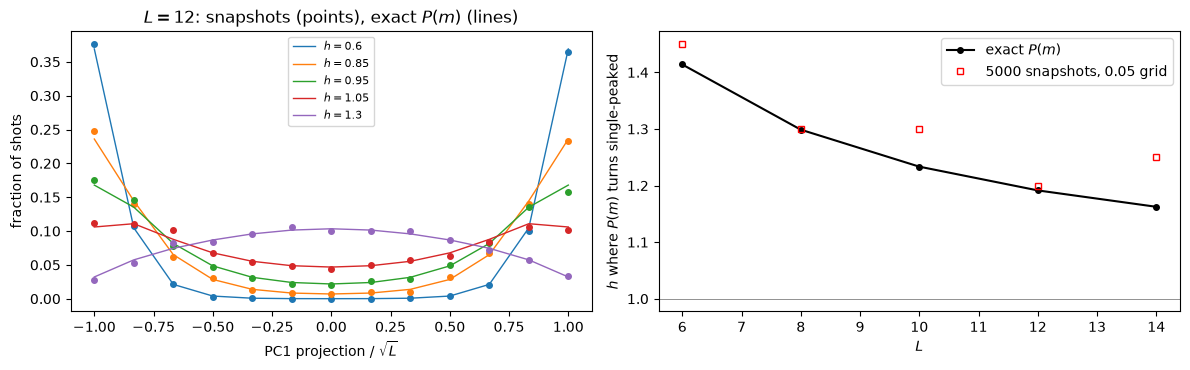


L=12, h=1.3: exact P(0) - P(1/6) = 0.0019,  shot noise on that difference ~ 0.0064


In [7]:
def is_unimodal(w, L):
    # w: weights over the L+1 values of m (even L). Fold +m and -m first: taking the larger of two
    # noisy bins would bias a snapshot histogram toward "two peaks".
    w = (w + w[::-1]) / 2
    return np.argmax(w) == L // 2

def hist_pc1(X):
    L = X.shape[1]
    _, _, proj = tfim.pca(X)
    x = proj[:, 0] / np.sqrt(L)
    return np.bincount(np.clip(np.round((x + 1) * L / 2), 0, L).astype(int), minlength=L + 1)

def exact_Pm(L, h):
    return np.bincount(np.round((tfim.magnetization(L) + 1) * L / 2).astype(int), weights=exact_p(L, h),
                       minlength=L + 1)

def h_split_exact(L, lo=0.5, hi=1.5):
    for _ in range(30):                      # bisection on the field where P(m) turns unimodal
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if is_unimodal(exact_Pm(L, mid), L) else (mid, hi)
    return (lo + hi) / 2

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
mv = np.linspace(-1, 1, 13)
chi2, dof = 0, 0
for j, h in enumerate([0.6, 0.85, 0.95, 1.05, 1.3]):
    n_obs, P = hist_pc1(SNAP[12, h]), exact_Pm(12, h)
    ax[0].plot(mv, n_obs / M_SNAP, 'o', color=f'C{j}', ms=4)
    ax[0].plot(mv, P, '-', color=f'C{j}', lw=1, label=f'$h={h}$')
    use = M_SNAP * P >= 5                       # Pearson chi^2 over bins with enough expected counts
    chi2 += ((n_obs[use] - M_SNAP * P[use])**2 / (M_SNAP * P[use])).sum()
    dof += use.sum() - 1
ax[0].set_xlabel(r'PC1 projection / $\sqrt{L}$'); ax[0].set_ylabel('fraction of shots')
ax[0].set_title('$L=12$: snapshots (points), exact $P(m)$ (lines)'); ax[0].legend(fontsize=8)
check('PC1 histograms match the exact P(m) (Pearson chi^2)', abs(chi2 - dof) < 3 * np.sqrt(2 * dof),
      f'chi2 = {chi2:.1f} for {dof} dof')

print(f"\n{'L':>3} {'snapshots: first one-peak h':>28} {'exact':>7}")
hs_ex, hs_sn = [], []
for L in LS:
    uni = np.array([is_unimodal(hist_pc1(SNAP[L, h]), L) for h in H_GRID])
    hs_sn.append(H_GRID[np.argmax(uni)]); hs_ex.append(h_split_exact(L))
    print(f"{L:>3} {hs_sn[-1]:28.2f} {hs_ex[-1]:7.4f}")
ax[1].plot(LS, hs_ex, 'ko-', ms=4, label='exact $P(m)$')
ax[1].plot(LS, hs_sn, 'rs', ms=5, mfc='none', label=f'{M_SNAP} snapshots, 0.05 grid')
ax[1].axhline(1, color='gray', lw=0.6); ax[1].legend()
ax[1].set_xlabel('$L$'); ax[1].set_ylabel('$h$ where $P(m)$ turns single-peaked')
plt.tight_layout(); plt.show()

P = exact_Pm(12, 1.3)
print(f"\nL=12, h=1.3: exact P(0) - P(1/6) = {P[6] - P[5]:.4f},  shot noise on that difference ~ {np.sqrt((P[6] + P[5]) / M_SNAP):.4f}")

By eye the change from two peaks to one is obvious, and the snapshot histograms agree with the exact $P(m)$ bin
by bin. *Locating* the change from snapshots is a different matter. Near the change the top of $P(m)$ is almost
flat: at $L=12$, $h=1.3$ the center beats its neighbors by 0.2% of the shots, while the shot noise on that
difference is 0.6%. So the snapshot estimates land only within a grid step or two of the exact ones. There is no
check on them, because "first grid point where a noisy histogram looks single-peaked" has no honest error bar.

The exact curve is informative anyway. The change sits *above* $h_c$ and drifts down toward it as $L$ grows
(1.41 at $L=6$, 1.16 at $L=14$). Just above $h_c$ the correlation length is longer than these chains, so a short
chain still looks ordered. Step 5 handles the same finite-size drift properly.

## Step 4 — What PCA actually computed

The ground state is translation invariant, so the covariance depends only on the distance,
$C_{ij}=G(i-j)$: a **circulant** matrix. Every circulant matrix is diagonalized by the Fourier modes
$f_k(j)=e^{ikj}/\sqrt L$, $k=2\pi n/L$, with eigenvalues
$$S(k)=\sum_r e^{ikr}G(r),$$
the static structure factor. So PCA did not have to discover the eigenvectors; symmetry fixes them. All PCA
decides is the *order*, and in a ferromagnet $S(k)$ peaks at $k=0$. "PCA found the order parameter" means
"$S(0)$ dominates the spectrum". And $S(0)=\sum_rG(r)=L\langle m^2\rangle$ is Step 3 again.

A second way to read $S(k)$ makes the statistics simple. Each shot has a Fourier power
$q_k=\frac1L|\sum_j e^{ikj}s_j|^2$, and $S(k)=\langle q_k\rangle$. So the snapshot estimate of $S(k)$ is a sample mean
with error $\mathrm{std}(q_k)/\sqrt M$, exactly like EVR₁.

In [8]:
worst = 0
for L in [8, 12, 14]:
    for h in [0.3, 1.0, 2.0]:
        lam = tfim.pca_cov(tfim.exact_cov(exact_p(L, h)))[0]
        S = tfim.structure_factor(tfim.correlator(exact_p(L, h)))[1]
        worst = max(worst, np.abs(lam - np.sort(S)[::-1]).max())
check('PCA of the exact covariance = exact S(k), sorted', worst < 1e-12, f'max |diff| = {worst:.1e}')

L, h, M4 = 12, 1.0, 20000
X4 = tfim.snapshots(gs(L, h), M4, np.random.default_rng(4))
lam4, V4, _ = tfim.pca(X4)
k, S_ex = tfim.structure_factor(tfim.correlator(exact_p(L, h)))
q = np.abs(X4 @ np.exp(1j * np.outer(np.arange(L), k)))**2 / L          # per-shot Fourier power, (M, L)
S_sn, S_err = q.mean(0), q.std(0) / np.sqrt(M4)

print(f"L={L}, h={h}, M={M4}")
print(f"{'':>20}" + ''.join(f'{x:7.3f}' for x in np.sort(S_ex)[::-1]) + '   <- exact S(k), largest first')
print(f"{'PCA eigenvalues':>20}" + ''.join(f'{x:7.3f}' for x in lam4))
print(f"\n{'n':>3} {'k/pi':>6} {'exact S(k)':>11} {'<q_k> shots':>12} {'error':>7} {'z':>6}")
half = np.arange(L // 2 + 1)                     # S(k) = S(-k): n and L-n are the same number
for n in half:
    print(f"{n:>3} {k[n] / np.pi:6.3f} {S_ex[n]:11.4f} {S_sn[n]:12.4f} {S_err[n]:7.4f} {(S_sn[n] - S_ex[n]) / S_err[n]:+6.2f}")
z = (S_sn[half] - S_ex[half]) / S_err[half]
check('snapshot S(k) = exact S(k) within Monte Carlo error',
      abs(np.mean(z**2) - 1) < 3 * np.sqrt(2 / len(z)) and np.abs(z).max() < 3.5,
      f'chi2/dof = {np.mean(z**2):.2f} over {len(z)} independent k')

# Which |k| does each sample PC live at?  Weight of PC j on the Fourier pair +-k_n.
W = np.abs(np.exp(-1j * np.outer(k, np.arange(L))) @ V4)**2 / L            # (k, PC)
Wpair = np.array([W[n] + (W[L - n] if 0 < n < L - n else 0) for n in half])  # fold +-k
dom = Wpair.argmax(0)
print("\nPC:                    " + ''.join(f'{j + 1:6d}' for j in range(L)))
print("dominant n, k=2 pi n/L: " + ''.join(f'{dom[j]:6d}' for j in range(L)))
print("weight on that +-k pair:" + ''.join(f'{Wpair[dom[j], j]:6.3f}' for j in range(L)))
check('PC1 is k=0 and PC2, PC3 are the k = +-2pi/L pair',
      dom[0] == 0 and set(dom[1:3]) == {1} and Wpair[0, 0] > 0.999 and Wpair[1, 1:3].min() > 0.99,
      f'weights {Wpair[0, 0]:.4f}, {Wpair[1, 1]:.4f}, {Wpair[1, 2]:.4f}')

CHECK PCA of the exact covariance = exact S(k), sorted: PASS   max |diff| = 1.5e-14
L=12, h=1.0, M=20000
                      6.721  0.908  0.908  0.536  0.536  0.401  0.401  0.338  0.338  0.307  0.307  0.298   <- exact S(k), largest first
     PCA eigenvalues  6.728  0.915  0.904  0.537  0.533  0.401  0.394  0.341  0.334  0.310  0.303  0.299

  n   k/pi  exact S(k)  <q_k> shots   error      z
  0  0.000      6.7213       6.7276  0.0293  +0.21
  1  0.167      0.9082       0.9092  0.0085  +0.12
  2  0.333      0.5356       0.5351  0.0047  -0.10
  3  0.500      0.4012       0.3970  0.0034  -1.23
  4  0.667      0.3377       0.3372  0.0030  -0.16
  5  0.833      0.3075       0.3073  0.0028  -0.05
  6  1.000      0.2984       0.3008  0.0035  +0.67
CHECK snapshot S(k) = exact S(k) within Monte Carlo error: PASS   chi2/dof = 0.30 over 7 independent k

PC:                         1     2     3     4     5     6     7     8     9    10    11    12
dominant n, k=2 pi n/L:      0     1     1   

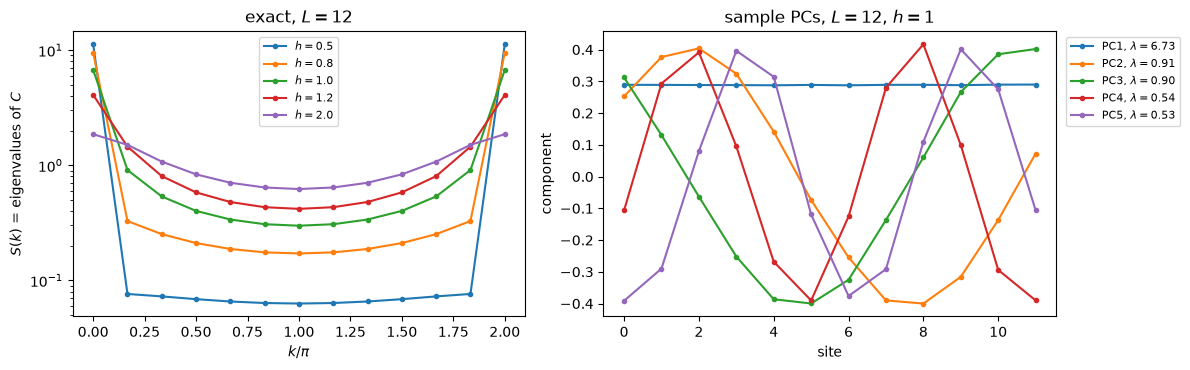

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
kk = np.linspace(0, 2 * np.pi, 13)
for j, h in enumerate([0.5, 0.8, 1.0, 1.2, 2.0]):
    k, S = tfim.structure_factor(tfim.correlator(exact_p(12, h)))
    ax[0].semilogy(np.append(k, 2 * np.pi) / np.pi, np.append(S, S[0]), 'o-', color=f'C{j}', ms=3, label=f'$h={h}$')
ax[0].set_xlabel(r'$k/\pi$'); ax[0].set_ylabel('$S(k)$ = eigenvalues of $C$'); ax[0].set_title('exact, $L=12$')
ax[0].legend(fontsize=8)
for j in range(5):
    ax[1].plot(np.arange(12), V4[:, j] * np.sign(V4[np.argmax(np.abs(V4[:, j])), j]), 'o-', ms=3,
               label=f'PC{j + 1}, $\\lambda={lam4[j]:.2f}$')
ax[1].set_xlabel('site'); ax[1].set_ylabel('component'); ax[1].set_title('sample PCs, $L=12$, $h=1$')
ax[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

The PCA spectrum is the structure factor, pair by pair. The eigenvalues come in pairs because $S(k)=S(-k)$.
Within a pair PCA returns some rotation of $\cos kj$ and $\sin kj$; with finite $M$ the pair is split slightly
and the rotation is random. The higher pairs (0.338, 0.307, 0.298 exactly) are so close that sample PCs there
can mix different $|k|$. That is why the check above only tests the top three, where the gaps are large. As $h$
grows, $S(k)$ flattens and the $k=0$ peak stops dominating, which is the whole content of the EVR₁ curve.

### The limitation: PCA only sees $\langle Z_iZ_j\rangle$

Everything PCA computes comes from the covariance. Any data set with the same covariance gives the same answer.
Draw Gaussian vectors with the exact $C$ at $h=0.8$, $L=12$, and compare with real snapshots.

L=12, h=0.8, M=20000
              lambda_1  lambda_2    EVR1   Binder U  error U


   snapshots     9.522     0.334  0.7935     0.6314   0.0005
    Gaussian     9.526     0.332  0.7938    -0.0040   0.0113
       exact     9.523     0.327  0.7936     0.6314
CHECK Gaussian surrogate has the same S(k), i.e. the same PCA: PASS   chi2/dof = 0.74
CHECK ... but a completely different Binder cumulant: PASS   U(snapshots) - U(Gaussian) = 0.635


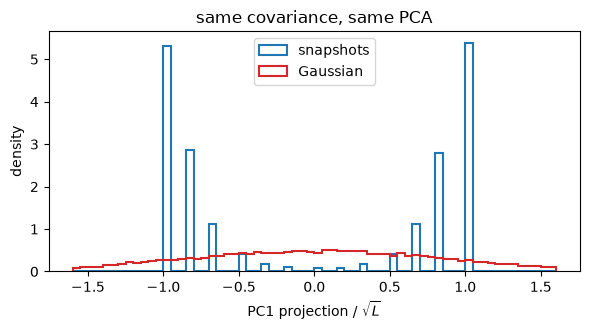

In [10]:
L, h, M4 = 12, 0.8, 20000
C_ex = tfim.exact_cov(exact_p(L, h))
rng = np.random.default_rng(44)
Xs = tfim.snapshots(gs(L, h), M4, rng).astype(float)
Xg = rng.multivariate_normal(np.zeros(L), C_ex, size=M4)
k = 2 * np.pi * np.arange(L) / L
F = np.exp(1j * np.outer(np.arange(L), k))
print(f"L={L}, h={h}, M={M4}")
print(f"{'':>12} {'lambda_1':>9} {'lambda_2':>9} {'EVR1':>7} {'Binder U':>10} {'error U':>8}")
res = {}
for name, X in [('snapshots', Xs), ('Gaussian', Xg)]:
    lam = tfim.pca(X)[0]
    m = X.mean(1)
    U = tfim.binder((m**2).mean(), (m**4).mean())
    # bootstrap error on U
    b = np.random.default_rng(0).integers(0, M4, (200, M4))
    Ub = tfim.binder((m[b]**2).mean(1), (m[b]**4).mean(1))
    S_hat = (np.abs(X @ F)**2 / L)
    res[name] = (U, Ub.std(), S_hat.mean(0), S_hat.std(0) / np.sqrt(M4), X)
    print(f"{name:>12} {lam[0]:9.3f} {lam[1]:9.3f} {lam[0] / lam.sum():7.4f} {U:10.4f} {Ub.std():8.4f}")
m2_ex, m4_ex = tfim.exact_moments(exact_p(L, h))
print(f"{'exact':>12} {np.sort(np.linalg.eigvalsh(C_ex))[-1]:9.3f} {np.sort(np.linalg.eigvalsh(C_ex))[-2]:9.3f} "
      f"{m2_ex:7.4f} {tfim.binder(m2_ex, m4_ex):10.4f}")

S_ex = tfim.structure_factor(tfim.correlator(exact_p(L, h)))[1]
half = np.arange(L // 2 + 1)
zg = (res['Gaussian'][2][half] - S_ex[half]) / res['Gaussian'][3][half]
check('Gaussian surrogate has the same S(k), i.e. the same PCA', np.mean(zg**2) < 1 + 3 * np.sqrt(2 / len(zg)),
      f'chi2/dof = {np.mean(zg**2):.2f}')
dU = res['snapshots'][0] - res['Gaussian'][0]
check('... but a completely different Binder cumulant', dU / np.hypot(res['snapshots'][1], res['Gaussian'][1]) > 10,
      f'U(snapshots) - U(Gaussian) = {dU:.3f}')

fig, ax = plt.subplots(figsize=(6, 3.4))
for name, c in [('snapshots', 'C0'), ('Gaussian', 'C3')]:
    m = res[name][4].mean(1)
    ax.hist(m, bins=np.linspace(-1.6, 1.6, 65), density=True, histtype='step', color=c, lw=1.5, label=name)
ax.set_xlabel(r'PC1 projection / $\sqrt{L}$'); ax.set_ylabel('density'); ax.set_title('same covariance, same PCA')
ax.legend(); plt.tight_layout(); plt.show()

Both data sets give PCA the same spectrum and the same PC1, within shot noise. One is a cat state with two sharp
peaks and $U\approx0.6$; the other is a single Gaussian blob with $U\approx0$, and it is not even made of $\pm1$ spins.
PCA cannot tell them apart. The bimodality in Step 3 and the Binder cumulant in Step 5 are four-point information
that we read off *after* projecting on PC1. PCA found the axis; the physics along it is beyond what PCA computes.

## Step 5 — Locating $h_c$

The Binder cumulant $U_L=1-\langle m^4\rangle/(3\langle m^2\rangle^2)$ goes to $2/3$ in the ordered phase (two sharp peaks)
and to $0$ in the disordered phase (one Gaussian peak). At $h_c$ it is scale invariant, so the curves for
different $L$ cross there, up to corrections that vanish with $L$. Here $m$ is the PC1 projection divided by
$\sqrt L$, which is the snapshot mean once PC1 $=u$ (checked below). We project the *raw* snapshots, not the
centered ones: $\langle Z_i\rangle=0$ exactly by symmetry, and subtracting the sample mean $c\sim1/\sqrt M$ shifts $U$ by
$O(c^2)$. That is small (a few hundredths of $\sigma$ typically, see below), but in the worst of 93 data sets it
reaches half a standard error.

### Exact first

$U_L$ from $|\psi|^2$ on 81 fields in $[0.8,1.2]$; consecutive sizes are crossed by linear interpolation.

exact Binder sweep, 5 sizes x 81 fields: 5.4 s

   sizes  crossing   brief
  6, 8      0.9284  0.9284
  8, 10     0.9572  0.9572
 10, 12     0.9715  0.9715
 12, 14     0.9797  0.9797
CHECK exact Binder crossings match the brief: PASS   

fit h* = h_c + a / Lbar^2:  all four pairs h_c = 1.0008 (a = -3.55),  last three h_c = 1.0005
CHECK extrapolated h_c = 1 to within 1e-3: PASS   1.0008, 1.0005


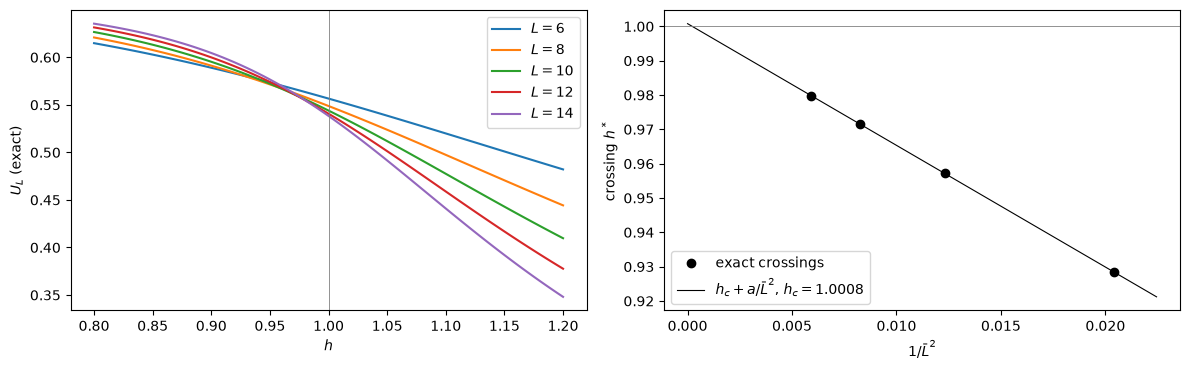

In [11]:
H_B = np.round(np.linspace(0.8, 1.2, 81), 6)
t0 = time.time()
U_EX = {L: np.array([tfim.binder(*tfim.exact_moments(exact_p(L, h))) for h in H_B]) for L in LS}
print(f'exact Binder sweep, {len(LS)} sizes x {len(H_B)} fields: {time.time() - t0:.1f} s')

def lin_crossing(D, H):
    # first sign change of D on the grid, linearly interpolated
    i = np.flatnonzero(np.sign(D[:-1]) != np.sign(D[1:]))[0]
    return H[i] + D[i] * (H[i + 1] - H[i]) / (D[i] - D[i + 1])

pairs = list(zip(LS[:-1], LS[1:]))
ref = {(6, 8): 0.9284, (8, 10): 0.9572, (10, 12): 0.9715, (12, 14): 0.9797}
hstar = np.array([lin_crossing(U_EX[b] - U_EX[a], H_B) for a, b in pairs])
Lbar = np.array([(a + b) / 2 for a, b in pairs])
print(f"\n{'sizes':>8} {'crossing':>9} {'brief':>7}")
for (a, b), x in zip(pairs, hstar):
    print(f"{a:>3}, {b:<3} {x:9.4f} {ref[a, b]:7.4f}")
check('exact Binder crossings match the brief', all(abs(x - ref[p]) < 1e-4 for p, x in zip(pairs, hstar)))

A = np.stack([np.ones_like(Lbar), Lbar**-2], 1)
hc_all = np.linalg.lstsq(A, hstar, rcond=None)[0]
hc_3 = np.linalg.lstsq(A[1:], hstar[1:], rcond=None)[0]
print(f"\nfit h* = h_c + a / Lbar^2:  all four pairs h_c = {hc_all[0]:.4f} (a = {hc_all[1]:.2f}),  last three h_c = {hc_3[0]:.4f}")
check('extrapolated h_c = 1 to within 1e-3', abs(hc_all[0] - 1) < 1e-3 and abs(hc_3[0] - 1) < 1e-3,
      f'{hc_all[0]:.4f}, {hc_3[0]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for L in LS:
    ax[0].plot(H_B, U_EX[L], label=f'$L={L}$')
ax[0].axvline(1, color='gray', lw=0.6); ax[0].set_xlabel('$h$'); ax[0].set_ylabel('$U_L$ (exact)'); ax[0].legend()
x = np.linspace(0, Lbar.min()**-2 * 1.1, 50)
ax[1].plot(Lbar**-2, hstar, 'ko', label='exact crossings')
ax[1].plot(x, hc_all[0] + hc_all[1] * x, 'k-', lw=0.8, label=f'$h_c + a/\\bar L^2$, $h_c={hc_all[0]:.4f}$')
ax[1].axhline(1, color='gray', lw=0.6)
ax[1].set_xlabel(r'$1/\bar L^2$'); ax[1].set_ylabel('crossing $h^*$'); ax[1].legend()
plt.tight_layout(); plt.show()

The crossings drift up toward 1 and the shortfall falls as $\bar L^{-2}$ ($1/\nu+\omega=2$ for the Ising class).
A two-parameter fit lands within $10^{-3}$ of $h_c=1$. Note how far the raw crossings are from 1: $3\%$ for
$(10,12)$, $2\%$ even for $(12,14)$. Without the extrapolation, these sizes cannot locate $h_c$ to better than a
few percent, however good the data.

### Then from snapshots only

An experiment would measure $U_L$ from shots on a grid of fields and cross the noisy curves. Here: 31 fields
in $[0.85,1.15]$, sizes $(8,10)$ and $(10,12)$, $M$ shots per field.

Because $m$ takes only $L+1$ values, a set of $M$ shots is summarized without loss by the histogram of $m$, and a
bootstrap resample of the shots is a multinomial draw from that histogram. That makes 200 resamples cheap.

In [12]:
H_FIT = np.round(np.linspace(0.85, 1.15, 31), 6)
SIZES5, MS, NBOOT = [8, 10, 12], [2000, 10000, 50000], 200

def counts_m(X):
    L = X.shape[1]
    return np.bincount((X.sum(1).astype(int) + L) // 2, minlength=L + 1)

def U_counts(c, L):
    mv = np.linspace(-1, 1, L + 1)
    M = c.sum(-1)
    return tfim.binder(c @ mv**2 / M, c @ mv**4 / M)

def quad_root(D, H=H_FIT):
    # Root in the window of a quadratic fit to D(h). D has shape (n_h,) or (R, n_h).
    D2 = np.atleast_2d(D)
    a, b, c = np.polyfit(H - 1, D2.T, 2)
    disc = np.sqrt(np.maximum(b**2 - 4 * a * c, 0))
    r = np.stack([(-b + disc) / (2 * a), (-b - disc) / (2 * a)]) + 1
    lo, hi = H[0], H[-1]
    r = np.where((r >= lo) & (r <= hi), r, np.nan)
    out = np.where(np.isnan(r[0]), r[1], np.where(np.isnan(r[1]), r[0], np.fmin(r[0], r[1])))
    return out if np.ndim(D) == 2 else out[0]

def robust_sd(x):
    # half the 16-84% range: the quadratic root has occasional far outliers when a resample's fit is flat
    x = x[~np.isnan(x)]
    return (np.percentile(x, 84) - np.percentile(x, 16)) / 2

rng = np.random.default_rng(5)
t0 = time.time()
CNT, dev_raw, dev_cen = {}, [], []
for M in MS:
    for L in SIZES5:
        for h in H_FIT:
            X = tfim.snapshots(gs(L, h), M, rng)
            CNT[M, L, h] = counts_m(X)
            if M == 10000:          # m from PC1 vs the snapshot mean: compare the two Binder estimates
                _, V, proj = tfim.pca(X)
                U_m = U_counts(CNT[M, L, h], L)
                sig = np.std(U_counts(rng.multinomial(M, CNT[M, L, h] / M, size=NBOOT), L))
                for x, dev in [(X @ V[:, 0] / np.sqrt(L), dev_raw), (proj[:, 0] / np.sqrt(L), dev_cen)]:
                    dev.append(abs(tfim.binder((x**2).mean(), (x**4).mean()) - U_m) / sig)
print(f'snapshots for {len(MS)} M x {len(SIZES5)} L x {len(H_FIT)} fields: {time.time() - t0:.1f} s')
print(f'|U_PC1 - U_mean| in bootstrap sigma over {len(dev_raw)} sets at M = 10000:')
print(f'   raw snapshots on PC1:      median {np.median(dev_raw):.3f}, max {np.max(dev_raw):.3f}')
print(f'   centered snapshots on PC1: median {np.median(dev_cen):.3f}, max {np.max(dev_cen):.3f}')
check('Binder from PC1 projections = Binder from the snapshot mean', np.max(dev_raw) < 0.1,
      f'max {np.max(dev_raw):.3f} sigma')

U_FIT_EX = {L: np.array([tfim.binder(*tfim.exact_moments(exact_p(L, h))) for h in H_FIT]) for L in SIZES5}
exact_same = {(a, b): quad_root(U_FIT_EX[b] - U_FIT_EX[a]) for a, b in [(8, 10), (10, 12)]}
print(f"exact curves, same quadratic fit:  (8,10) {exact_same[8, 10]:.4f}   (10,12) {exact_same[10, 12]:.4f}")
check('exact crossings with the same quadratic fit match the brief',
      abs(exact_same[8, 10] - 0.9521) < 1e-4 and abs(exact_same[10, 12] - 0.9653) < 1e-4)

bt = np.random.default_rng(55)
print(f"\n{'shots per h':>11} {'sizes 8, 10':>16} {'sizes 10, 12':>16}")
SN, zmax = {}, 0
for M in MS:
    row = []
    for a, b in [(8, 10), (10, 12)]:
        Ua = np.array([U_counts(CNT[M, a, h], a) for h in H_FIT])
        Ub = np.array([U_counts(CNT[M, b, h], b) for h in H_FIT])
        Ua_bt = U_counts(np.stack([bt.multinomial(M, CNT[M, a, h] / M, size=NBOOT) for h in H_FIT], 1), a)
        Ub_bt = U_counts(np.stack([bt.multinomial(M, CNT[M, b, h] / M, size=NBOOT) for h in H_FIT], 1), b)
        x, s = quad_root(Ub - Ua), robust_sd(quad_root(Ub_bt - Ua_bt))
        SN[M, a, b] = (x, s)
        zmax = max(zmax, abs(x - exact_same[a, b]) / s)
        row.append(f'{x:.4f} ± {s:.4f}')
    print(f"{M:>11} {row[0]:>16} {row[1]:>16}")
print(f"{'exact, same fit':>11} {exact_same[8, 10]:16.4f} {exact_same[10, 12]:16.4f}")
check('snapshot crossings agree with the exact curves under the same fit', zmax < 3, f'max |z| = {zmax:.2f}')

snapshots for 3 M x 3 L x 31 fields: 0.5 s
|U_PC1 - U_mean| in bootstrap sigma over 93 sets at M = 10000:
   raw snapshots on PC1:      median 0.013, max 0.041
   centered snapshots on PC1: median 0.026, max 0.587
CHECK Binder from PC1 projections = Binder from the snapshot mean: PASS   max 0.041 sigma
exact curves, same quadratic fit:  (8,10) 0.9521   (10,12) 0.9653
CHECK exact crossings with the same quadratic fit match the brief: PASS   

shots per h      sizes 8, 10     sizes 10, 12
       2000  0.9688 ± 0.0239  0.9665 ± 0.0147
      10000  0.9574 ± 0.0082  0.9709 ± 0.0102
      50000  0.9505 ± 0.0030  0.9653 ± 0.0038
exact, same fit           0.9521           0.9653
CHECK snapshot crossings agree with the exact curves under the same fit: PASS   max |z| = 0.70


### Two traps

**The fit window moves the root.** A quadratic on $[0.85,1.15]$ puts the *exact* crossings at 0.9521 and 0.9653,
not 0.9572 and 0.9715. The curvature of $U_b-U_a$ over a window this wide is not quadratic. That shift (0.005)
is comparable to the error bar at $10^4$ shots, so the honest comparison for a snapshot crossing is the exact
curve *processed the same way*, as in the table above.

**The first sign change is biased low.** The tempting estimator is to walk up the grid and take the first
place where $U_b-U_a$ changes sign. On the low side both curves sit near $2/3$ and their difference is small, so
noise produces spurious early sign changes, and the estimate is always the *earliest* of them. To see the bias
rather than argue it, repeat the whole experiment 500 times at $M=2000$ (drawing histograms of $m$ from the
exact $P(m)$, which is what $M$ snapshots are) and compare the two estimators.

In [13]:
R, M = 500, 2000
rep = np.random.default_rng(6)
def Pm(L, h):
    return np.bincount((spins_sum[L] + L) // 2, weights=exact_p(L, h), minlength=L + 1)
spins_sum = {L: tfim.spins(L).sum(1).astype(int) for L in SIZES5}

print(f"{R} replicate experiments, M = {M} per field")
print(f"{'sizes':>8} {'estimator':>18} {'mean':>8} {'spread':>7} {'target':>8} {'bias / spread':>14}")
bias = {}
for a, b in [(8, 10), (10, 12)]:
    Ua = U_counts(np.stack([rep.multinomial(M, Pm(a, h), size=R) for h in H_FIT], 1), a)
    Ub = U_counts(np.stack([rep.multinomial(M, Pm(b, h), size=R) for h in H_FIT], 1), b)
    D = Ub - Ua
    first = np.array([lin_crossing(d, H_FIT) for d in D])
    quad = quad_root(D)
    target_lin = lin_crossing(U_FIT_EX[b] - U_FIT_EX[a], H_FIT)
    for name, est, tgt in [('first sign change', first, target_lin), ('quadratic root', quad, exact_same[a, b])]:
        est = est[~np.isnan(est)]
        bias[a, b, name] = (est.mean() - tgt) / (est.std() / np.sqrt(len(est))), (est.mean() - tgt) / est.std()
        print(f"{a:>3}, {b:<3} {name:>18} {est.mean():8.4f} {est.std():7.4f} {tgt:8.4f} {(est.mean() - tgt) / est.std():+14.2f}")
check('first sign change is biased low (>5 standard errors)',
      all(bias[a, b, 'first sign change'][0] < -5 for a, b in [(8, 10), (10, 12)]))
check('quadratic root is unbiased against the same-fit exact crossing (<3 standard errors)',
      all(abs(bias[a, b, 'quadratic root'][0]) < 3 for a, b in [(8, 10), (10, 12)]))

500 replicate experiments, M = 2000 per field
   sizes          estimator     mean  spread   target  bias / spread
  8, 10   first sign change   0.9062  0.0301   0.9571          -1.69
  8, 10      quadratic root   0.9518  0.0179   0.9521          -0.01
 10, 12   first sign change   0.9152  0.0341   0.9715          -1.65
 10, 12      quadratic root   0.9665  0.0188   0.9653          +0.07
CHECK first sign change is biased low (>5 standard errors): PASS   
CHECK quadratic root is unbiased against the same-fit exact crossing (<3 standard errors): PASS   


The first sign change lands about 1.7 of its own spreads low, and it is also the noisier estimator. In a single
experiment you would not notice: the bias is about the size of the error bar, so the result just looks unlucky.
Only the replicates show that it is low every time. The quadratic root lands on its target, so it is unbiased
once it is compared with the right target, which is the exact curve under the same fit.

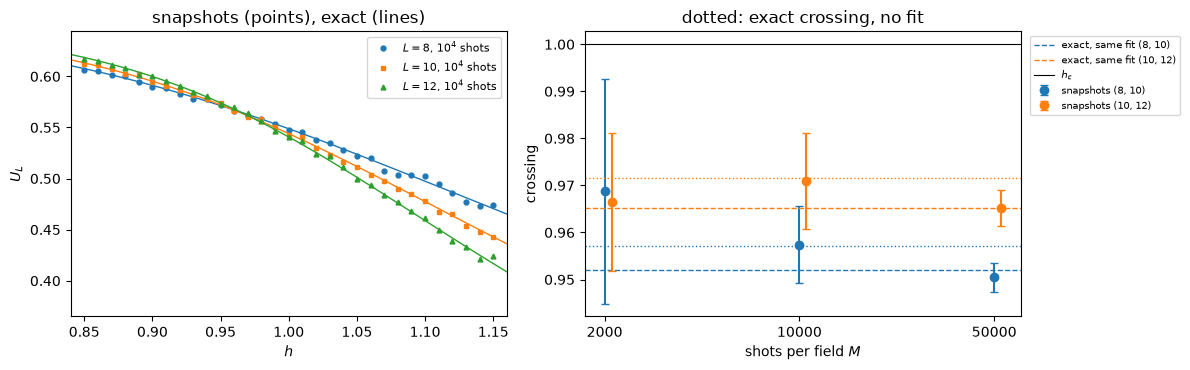

(10,12) at 10^4 shots: statistical error 0.0102 = 1.0% of h_c;  finite-size shortfall 1 - h* = 0.0285 = 2.8%


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (L, mk) in enumerate([(8, 'o'), (10, 's'), (12, '^')]):
    U = np.array([U_counts(CNT[10000, L, h], L) for h in H_FIT])
    ax[0].plot(H_FIT, U, mk, color=f'C{j}', ms=3.5, label=f'$L={L}$, $10^4$ shots')
    ax[0].plot(H_B, U_EX[L], '-', color=f'C{j}', lw=1)
ax[0].set_xlim(0.84, 1.16); ax[0].set_xlabel('$h$'); ax[0].set_ylabel('$U_L$'); ax[0].legend(fontsize=8)
ax[0].set_title('snapshots (points), exact (lines)')
for j, (a, b) in enumerate([(8, 10), (10, 12)]):
    xs = [SN[M, a, b][0] for M in MS]; es = [SN[M, a, b][1] for M in MS]
    ax[1].errorbar(np.array(MS) * (1 + 0.06 * j), xs, es, fmt='o', color=f'C{j}', capsize=3, label=f'snapshots ({a}, {b})')
    ax[1].axhline(exact_same[a, b], color=f'C{j}', ls='--', lw=1, label=f'exact, same fit ({a}, {b})')
    ax[1].axhline(hstar[pairs.index((a, b))], color=f'C{j}', ls=':', lw=1)
ax[1].axhline(1, color='k', lw=0.8, label='$h_c$')
ax[1].set_xscale('log'); ax[1].set_xticks(MS, [f'{M}' for M in MS]); ax[1].minorticks_off()
ax[1].set_xlabel('shots per field $M$'); ax[1].set_ylabel('crossing')
ax[1].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1)); ax[1].set_title('dotted: exact crossing, no fit')
plt.tight_layout(); plt.show()

s4 = SN[10000, 10, 12][1]
print(f"(10,12) at 10^4 shots: statistical error {s4:.4f} = {100 * s4:.1f}% of h_c;  "
      f"finite-size shortfall 1 - h* = {1 - hstar[pairs.index((10, 12))]:.4f} = {100 * (1 - hstar[pairs.index((10, 12))]):.1f}%")

**The bottleneck is system size, not shots.** At $10^4$ shots per field the crossing is pinned to about 1%,
while the crossing itself sits 3% below $h_c$ at $L\le12$. More shots shrink the error bar toward a number that
is still wrong by 3%. Only larger $L$, or the $\bar L^{-2}$ extrapolation (which needs several sizes, each
measured well), closes that gap. For an experiment the lesson is to spend the budget on more sizes, not more
shots at one size.

## Push Harder

Four variations, each predicted before it is measured.

### The antiferromagnet

**Prediction.** With $J=-1$ and even $L$, flipping every other spin ($\prod_{i\,\text{odd}}X_i$) turns $-Z_iZ_{i+1}$ into
$+Z_iZ_{i+1}$ and leaves $X_i$ alone. So $H(J=-1)$ is unitarily equivalent to $H(J=1)$, and the antiferromagnet's
snapshots are the ferromagnet's with every other bit flipped: $C_{\rm AF}=DC_{\rm F}D$, $D=\mathrm{diag}(+,-,+,-,\dots)$.
PC1 should be the staggered vector $Du$, the Fourier peak should sit at $k=\pi$, and the top eigenvalue should be
the ferromagnet's $L\langle m^2\rangle$.

In [15]:
L, h = 12, 0.3
E_af, psi_af = tfim.ground_state(L, h, J=-1)
p_af = tfim.probs(psi_af)
stag = (-1.0)**np.arange(L) / np.sqrt(L)
D = np.diag((-1.0)**np.arange(L))
X = tfim.snapshots(psi_af, M_SNAP, np.random.default_rng(7))
lam, V, _ = tfim.pca(X)
k, S_af = tfim.structure_factor(tfim.correlator(p_af))
m2_f = tfim.exact_moments(exact_p(L, h))[0]
ms = X @ stag / np.sqrt(L)                                   # staggered magnetization of each shot
err = np.std(ms**2) / np.sqrt(M_SNAP)
print(f"L={L}, h={h}, J=-1, M={M_SNAP}")
print(f"top PCA eigenvalues {np.round(lam[:3], 3)};  exact L<m^2> of the ferromagnet {L * m2_f:.3f}")
print(f"|PC1 . staggered| = {abs(V[:, 0] @ stag):.5f},  exact S(k) peaks at k/pi = {k[np.argmax(S_af)] / np.pi:.2f}")
print(f"PC1 = {np.round(V[:, 0] * np.sign(V[0, 0]) * np.sqrt(L), 2)} x 1/sqrt(L)")
check('AF: same E0 as the ferromagnet, and C_AF = D C_F D',
      abs(E_af - tfim.free_fermion_energy(L, h)) < 1e-10
      and np.abs(tfim.exact_cov(p_af) - D @ tfim.exact_cov(exact_p(L, h)) @ D).max() < 1e-12)
check('AF: PC1 is the staggered vector, the peak is at k = pi', abs(V[:, 0] @ stag) > 0.999 and np.argmax(S_af) == L // 2,
      f'overlap {abs(V[:, 0] @ stag):.5f}')
check("AF: EVR1 = the ferromagnet's exact <m^2> within MC error", abs(lam[0] / lam.sum() - m2_f) < 3 * err,
      f'{lam[0] / lam.sum():.4f} vs {m2_f:.4f} +- {err:.4f}')

L=12, h=0.3, J=-1, M=5000
top PCA eigenvalues [11.74   0.027  0.027];  exact L<m^2> of the ferromagnet 11.745
|PC1 . staggered| = 1.00000,  exact S(k) peaks at k/pi = 1.00
PC1 = [ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.] x 1/sqrt(L)
CHECK AF: same E0 as the ferromagnet, and C_AF = D C_F D: PASS   
CHECK AF: PC1 is the staggered vector, the peak is at k = pi: PASS   overlap 1.00000
CHECK AF: EVR1 = the ferromagnet's exact <m^2> within MC error: PASS   0.9788 vs 0.9787 +- 0.0011


Held exactly. PCA finds the staggered magnetization without being told about sublattices, but it has nothing
new to say: the model *is* the ferromagnet in a rotated frame, and PCA just finds the peak of $S(k)$ at $k=\pi$ in
place of $k=0$.

### A frustrated chain (ANNNI)

Add $+\kappa\sum_iZ_iZ_{i+2}$, which penalizes aligned next-nearest neighbors.

**Prediction.** At $h=0$ the ferromagnet has energy $-L+\kappa L$, the period-4 state $\uparrow\uparrow\downarrow\downarrow$ has
$0-\kappa L$, so for $\kappa>1/2$ the period-4 state wins. It has four translations, and its order parameter is the
Fourier amplitude at $k=\pm\pi/2$, which has two real components ($\cos$ and $\sin$). Translation invariance makes
$S(\pi/2)=S(-\pi/2)$ exactly, so PCA should return a **degenerate pair** at $k=\pi/2$ that carries almost all the
variance, with the sample splitting the pair at random. $L$ must be divisible by 4.

L=12, kappa=1.0, h=0.3, M=5000
PCA eigenvalues   [5.92  5.859 0.028 0.027]
exact eigenvalues [5.881 5.881 0.025 0.025]
weight of PC1, PC2, PC3 on k = +-pi/2: [1. 1. 0.]
CHECK ANNNI: ground state translation invariant, top pair degenerate (to solver precision): PASS   max |C_ij - G(i-j)| = 1.0e-11, |lambda_1 - lambda_2| = 1.2e-10
CHECK ANNNI: PC1 and PC2 live at k = +-pi/2: PASS   1.0000, 1.0000
CHECK ANNNI: snapshot S(pi/2) = exact within MC error: PASS   5.889 vs 5.881 +- 0.006


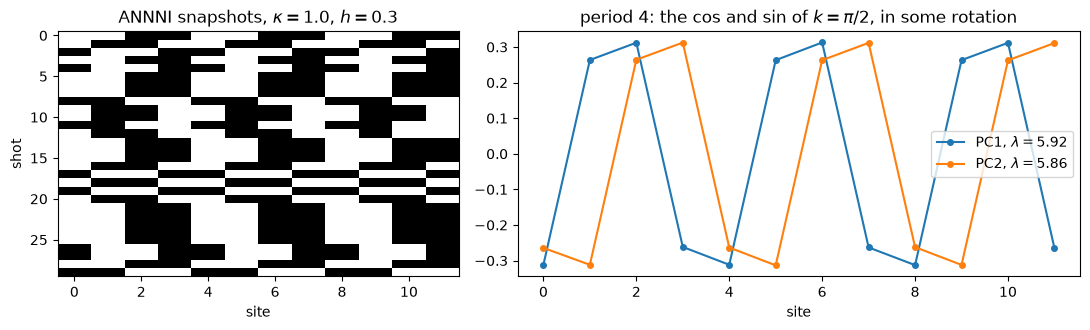

In [16]:
L, h, kap = 12, 0.3, 1.0
_, psi_nn = tfim.ground_state(L, h, kappa=kap)
p_nn = tfim.probs(psi_nn)
C_nn, G_nn = tfim.exact_cov(p_nn), tfim.correlator(p_nn)
circ = max(abs(C_nn[i, j] - G_nn[(j - i) % L]) for i in range(L) for j in range(L))
lam_ex = tfim.pca_cov(C_nn)[0]
X = tfim.snapshots(psi_nn, M_SNAP, np.random.default_rng(9))
lam, V, _ = tfim.pca(X)
k = 2 * np.pi * np.arange(L) / L
W = np.abs(np.exp(-1j * np.outer(k, np.arange(L))) @ V)**2 / L
w_pi2 = W[L // 4] + W[3 * L // 4]                            # weight on k = +-pi/2
q = np.abs(X @ np.exp(1j * k[L // 4] * np.arange(L)))**2 / L
S_pi2 = tfim.structure_factor(G_nn)[1][L // 4]
print(f"L={L}, kappa={kap}, h={h}, M={M_SNAP}")
print(f"PCA eigenvalues   {np.round(lam[:4], 3)}")
print(f"exact eigenvalues {np.round(lam_ex[:4], 3)}")
print(f"weight of PC1, PC2, PC3 on k = +-pi/2: {np.round(w_pi2[:3], 4)}")
check('ANNNI: ground state translation invariant, top pair degenerate (to solver precision)',
      circ < 1e-8 and abs(lam_ex[0] - lam_ex[1]) < 1e-8,
      f'max |C_ij - G(i-j)| = {circ:.1e}, |lambda_1 - lambda_2| = {abs(lam_ex[0] - lam_ex[1]):.1e}')
check('ANNNI: PC1 and PC2 live at k = +-pi/2', w_pi2[:2].min() > 0.99, f'{w_pi2[0]:.4f}, {w_pi2[1]:.4f}')
check('ANNNI: snapshot S(pi/2) = exact within MC error', abs(q.mean() - S_pi2) < 3 * q.std() / np.sqrt(M_SNAP),
      f'{q.mean():.3f} vs {S_pi2:.3f} +- {q.std() / np.sqrt(M_SNAP):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax[0].imshow(X[:30], cmap='gray', vmin=-1, vmax=1, aspect='auto', interpolation='nearest')
ax[0].set_title(f'ANNNI snapshots, $\\kappa={kap}$, $h={h}$'); ax[0].set_xlabel('site'); ax[0].set_ylabel('shot')
for j in range(2):
    ax[1].plot(np.arange(L), V[:, j], 'o-', ms=4, label=f'PC{j + 1}, $\\lambda={lam[j]:.2f}$')
ax[1].set_xlabel('site'); ax[1].legend(); ax[1].set_title('period 4: the cos and sin of $k=\\pi/2$, in some rotation')
plt.tight_layout(); plt.show()

Held. The pair is degenerate in the exact covariance and split only by sampling noise in the snapshots; the
two PCs are a random rotation of $\cos(\pi j/2+\phi)$ and $\sin(\pi j/2+\phi)$. Each snapshot is one of the four
translations of $\uparrow\uparrow\downarrow\downarrow$, and no single direction captures that, so PCA needs both.

Next, scan $(\kappa,h)$ and map which $k$ wins. This is exploratory. The ANNNI phase diagram between the
ferromagnet, the period-4 phase and the paramagnet includes an incommensurate (floating) region, and $L=12$
only allows $k$ in steps of $\pi/6$.

16 x 20 ground states at L=12: 3.4 s


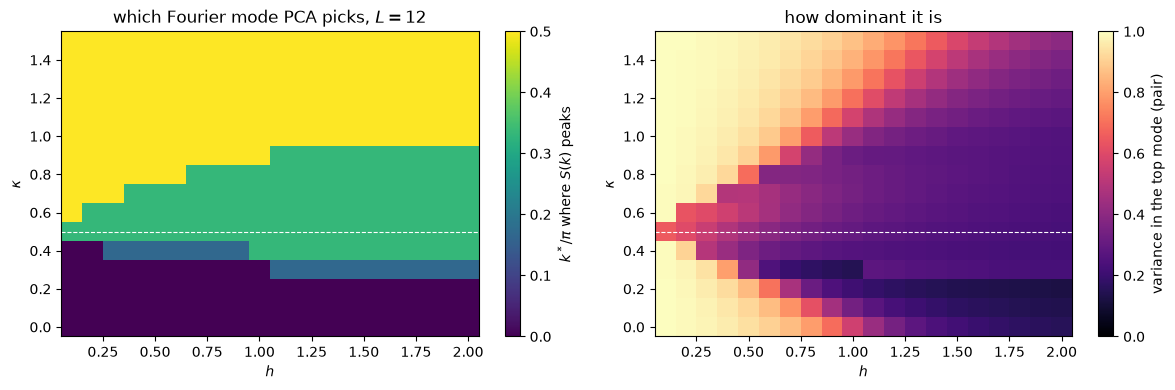

In [17]:
L = 12
KAP = np.round(np.arange(0, 1.51, 0.1), 6)
HH = np.round(np.arange(0.1, 2.01, 0.1), 6)
t0 = time.time()
kstar, frac = np.zeros((len(KAP), len(HH))), np.zeros((len(KAP), len(HH)))
for i, kap in enumerate(KAP):
    for j, h in enumerate(HH):
        k, S = tfim.structure_factor(tfim.correlator(tfim.probs(tfim.ground_state(L, h, kappa=kap)[1])))
        n = np.argmax(S[:L // 2 + 1])
        kstar[i, j] = k[n] / np.pi
        frac[i, j] = S[n] * (1 if n in (0, L // 2) else 2) / L   # count both members of a +-k pair
print(f'{len(KAP)} x {len(HH)} ground states at L={L}: {time.time() - t0:.1f} s')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].pcolormesh(HH, KAP, kstar, shading='nearest', cmap='viridis')
plt.colorbar(im, ax=ax[0], label=r'$k^*/\pi$ where $S(k)$ peaks')
im = ax[1].pcolormesh(HH, KAP, frac, shading='nearest', cmap='magma', vmin=0, vmax=1)
plt.colorbar(im, ax=ax[1], label='variance in the top mode (pair)')
for a in ax:
    a.set_xlabel('$h$'); a.set_ylabel(r'$\kappa$'); a.axhline(0.5, color='w', lw=0.8, ls='--')
ax[0].set_title('which Fourier mode PCA picks, $L=12$'); ax[1].set_title('how dominant it is')
plt.tight_layout(); plt.show()

Two ordered regions show up where one mode dominates (right panel, bright). For $\kappa<1/2$ at small $h$ PCA
picks $k=0$: the ferromagnet. For $\kappa>1/2$ at small $h$ it picks the $k=\pi/2$ pair: the period-4 phase, whose
edge moves to larger $\kappa$ as $h$ grows. Right at $\kappa=1/2$, $h\to0$, neither dominates: that is the multiphase
point, where the domain-wall cost $2-4\kappa$ vanishes. Everywhere else the variance is spread out, but the peak
of $S(k)$ still moves, to $\pi/6$ or $\pi/3$, the only incommensurate wavevectors a 12-site ring allows. Some of
that is the floating phase near $\kappa\approx1/2$. Some of it is a plain paramagnet whose short-range correlations
oscillate instead of decaying monotonically. $L=12$ cannot tell the two apart. The map says *where PCA's answer
changes*, not where the phase boundaries are. Locating them needs the finite-size analysis of Step 5, done
separately for each boundary, which is a project of its own.

### Readout error

Real detectors misread each atom with probability $\epsilon$ of a few percent.

**Prediction.** A flip multiplies $s_i$ by an independent $\eta_i=\pm1$ with $\langle\eta\rangle=1-2\epsilon$. Then
$C_{ij}\to(1-2\epsilon)^2C_{ij}$ for $i\ne j$ while $C_{ii}=1$ stays. So $C\to(1-2\epsilon)^2C+[1-(1-2\epsilon)^2]I$: the
eigenvectors do not change, and $\lambda\to(1-2\epsilon)^2\lambda+1-(1-2\epsilon)^2$. EVR₁ is pulled toward $1/L$, and the
relation inverts to correct it.

In [18]:
L, h, M, eps = 12, 0.8, 20000, 0.03
f = (1 - 2 * eps)**2
rng = np.random.default_rng(8)
X = tfim.snapshots(gs(L, h), M, rng)
Xn = tfim.flip_bits(X, eps, rng)
off = ~np.eye(L, dtype=bool)
def cov(X):
    Xc = X - X.mean(0); return Xc.T @ Xc / len(X)
c0, c1 = cov(X.astype(float))[off].mean(), cov(Xn.astype(float))[off].mean()
p = exact_p(L, h)
Cn = tfim.exact_cov(tfim.readout_noise(p, eps))
m2 = tfim.exact_moments(p)[0]
lam0, lam1 = tfim.pca(X)[0], tfim.pca(Xn)[0]
e0, e1 = lam0[0] / lam0.sum(), lam1[0] / lam1.sum()
e_corr = (e1 - (1 - f) / L) / f
err = np.std(Xn.mean(1)**2) / np.sqrt(M) / f
print(f"L={L}, h={h}, eps={eps}, M={M}")
print(f"mean off-diagonal C: {c0:.4f} -> {c1:.4f}, ratio {c1 / c0:.4f}  (predicted (1-2eps)^2 = {f:.4f})")
print(f"EVR1: clean {e0:.4f}, with readout error {e1:.4f}, predicted {f * m2 + (1 - f) / L:.4f}")
print(f"EVR1 corrected: {e_corr:.4f} +- {err:.4f},  exact <m^2> = {m2:.4f}")
check('readout: exact noisy covariance = (1-2eps)^2 C + [1-(1-2eps)^2] I',
      np.abs(Cn - (f * tfim.exact_cov(p) + (1 - f) * np.eye(L))).max() < 1e-12)
check('readout: corrected EVR1 = exact <m^2> within MC error', abs(e_corr - m2) < 3 * err)

L=12, h=0.8, eps=0.03, M=20000
mean off-diagonal C: 0.7747 -> 0.6857, ratio 0.8851  (predicted (1-2eps)^2 = 0.8836)
EVR1: clean 0.7935, with readout error 0.7119, predicted 0.7109
EVR1 corrected: 0.7948 +- 0.0022,  exact <m^2> = 0.7936
CHECK readout: exact noisy covariance = (1-2eps)^2 C + [1-(1-2eps)^2] I: PASS   
CHECK readout: corrected EVR1 = exact <m^2> within MC error: PASS   


**What uncorrected readout error does to the Binder crossing.** Each misread adds independent $\pm$ noise of
variance $\sim\epsilon/L$ to $m$, on top of a signal $\langle m^2\rangle\sim L^{-2\beta/\nu}=L^{-1/4}$. The noise is relatively
larger for *smaller* $L$, which pulls the small-$L$ Binder curve down more, so the crossing should move **up**.
Computed exactly by pushing $|\psi|^2$ through the readout channel:

In [19]:
EPS = [0, 0.01, 0.03, 0.05]
print(f"{'eps':>5}" + ''.join(f'{f"({a},{b})":>9}' for a, b in pairs) + f"{'h_c fit':>9}")
for eps in EPS:
    U = {L: np.array([tfim.binder(*tfim.exact_moments(tfim.readout_noise(exact_p(L, h), eps))) for h in H_B])
         for L in LS}
    hs = np.array([lin_crossing(U[b] - U[a], H_B) for a, b in pairs])
    hc = np.linalg.lstsq(A, hs, rcond=None)[0][0]
    print(f"{eps:>5}" + ''.join(f'{x:9.4f}' for x in hs) + f'{hc:9.4f}')
    if eps == 0.03: hc_03 = hc
check('uncorrected readout error moves the extrapolated h_c above 1', hc_03 > 1.005, f'h_c = {hc_03:.4f} at eps = 0.03')

  eps    (6,8)   (8,10)  (10,12)  (12,14)  h_c fit


    0   0.9284   0.9572   0.9715   0.9797   1.0008


 0.01   0.9385   0.9646   0.9771   0.9841   1.0030


 0.03   0.9561   0.9780   0.9875   0.9923   1.0081


 0.05   0.9710   0.9899   0.9971   1.0002   1.0136
CHECK uncorrected readout error moves the extrapolated h_c above 1: PASS   h_c = 1.0081 at eps = 0.03


Readout error makes the raw crossings look *better*: closer to $h_c=1$, so an experiment would be pleased.
Then the extrapolation overshoots. Correct it. A misread changes the number of up spins $n$ by a known kernel
$K[n',n]$ (`tfim.readout_kernel`), so the true histogram of $m$ is $K^{-1}$ applied to the measured one. That is
linear in the counts, so every moment is corrected without bias, at the price of some noise amplification.

In [20]:
eps, M = 0.03, 10000
Kinv = {L: np.linalg.inv(tfim.readout_kernel(L, eps)) for L in SIZES5}
worst_fwd, worst_inv = 0, 0
for L in SIZES5:
    for h in [0.9, 1.0, 1.1]:
        Pn_exact = np.bincount((spins_sum[L] + L) // 2, weights=tfim.readout_noise(exact_p(L, h), eps),
                               minlength=L + 1)          # histogram of the exact noisy bit-string distribution
        worst_fwd = max(worst_fwd, np.abs(tfim.readout_kernel(L, eps) @ Pm(L, h) - Pn_exact).max())
        worst_inv = max(worst_inv, np.abs(Kinv[L] @ Pn_exact - Pm(L, h)).max())
check('readout: K maps the exact P(m) to the P(m) of the exact noisy distribution', worst_fwd < 1e-12,
      f'max |diff| = {worst_fwd:.1e}')
check('readout: K^-1 applied to the noisy P(m) gives back the exact P(m)', worst_inv < 1e-12, f'max |diff| = {worst_inv:.1e}')

rng = np.random.default_rng(10)
CN = {(L, h): counts_m(tfim.flip_bits(tfim.snapshots(gs(L, h), M, rng), eps, rng)) for L in [10, 12] for h in H_FIT}
res = {}
for name, fix in [('uncorrected', lambda c, L: c), ('corrected', lambda c, L: c @ Kinv[L].T)]:
    U = {L: np.array([U_counts(fix(CN[L, h], L), L) for h in H_FIT]) for L in [10, 12]}
    Ubt = {L: U_counts(fix(np.stack([bt.multinomial(M, CN[L, h] / M, size=NBOOT) for h in H_FIT], 1), L), L)
           for L in [10, 12]}
    res[name] = (quad_root(U[12] - U[10]), robust_sd(quad_root(Ubt[12] - Ubt[10])))
U_noisy_ex = {L: np.array([tfim.binder(*tfim.exact_moments(tfim.readout_noise(exact_p(L, h), eps))) for h in H_FIT])
              for L in [10, 12]}
target_noisy = quad_root(U_noisy_ex[12] - U_noisy_ex[10])
print(f"sizes (10, 12), eps = {eps}, {M} shots per field, same quadratic fit:")
print(f"  uncorrected  {res['uncorrected'][0]:.4f} +- {res['uncorrected'][1]:.4f}   exact noisy curves {target_noisy:.4f}")
print(f"  corrected    {res['corrected'][0]:.4f} +- {res['corrected'][1]:.4f}   exact clean curves {exact_same[10, 12]:.4f}")
check('readout: uncorrected crossing = exact noisy crossing, corrected = exact clean crossing (within 3 sigma)',
      abs(res['uncorrected'][0] - target_noisy) < 3 * res['uncorrected'][1]
      and abs(res['corrected'][0] - exact_same[10, 12]) < 3 * res['corrected'][1])

CHECK readout: K maps the exact P(m) to the P(m) of the exact noisy distribution: PASS   max |diff| = 1.7e-16
CHECK readout: K^-1 applied to the noisy P(m) gives back the exact P(m): PASS   max |diff| = 2.8e-16
sizes (10, 12), eps = 0.03, 10000 shots per field, same quadratic fit:
  uncorrected  0.9798 +- 0.0073   exact noisy curves 0.9834
  corrected    0.9622 +- 0.0075   exact clean curves 0.9653
CHECK readout: uncorrected crossing = exact noisy crossing, corrected = exact clean crossing (within 3 sigma): PASS   


### The wrong basis

Measure in $x$ instead: a Hadamard on every site before readout, $\psi_x=H^{\otimes L}\psi$ (`tfim.x_basis`, a reshape to
$[2]^L$ and one `tensordot` per axis).

**Prediction.** The field points along $x$, so every $x$-snapshot leans toward $+1$, more so at larger $h$. But $X_i$
is not the order parameter. Its connected correlations $\langle X_iX_j\rangle-\langle X\rangle^2$ are short-ranged on *both*
sides of the transition. So the centered covariance has no dominant direction, and EVR₁ should stay small at
every $h$. The transition is in $\langle X\rangle$ itself (by Hellmann–Feynman, $\langle X\rangle=-\frac1L\partial E_0/\partial h$, whose
derivative is singular at $h_c$), and that is exactly the mean that centering throws away.

x basis, L=12: exact EVR1 between 0.085 and 0.164 for h in [0.3, 2]  (1/L = 0.083)
<X> at h=1: snapshots 0.6371 +- 0.0041, Hellmann-Feynman 0.6384
CHECK x basis: no dominant component (exact EVR1 < 0.2 for all h in [0.3, 2]): PASS   
CHECK x basis: <X> from snapshots = Hellmann-Feynman within MC error: PASS   chi2/dof = 0.88 over 39 fields


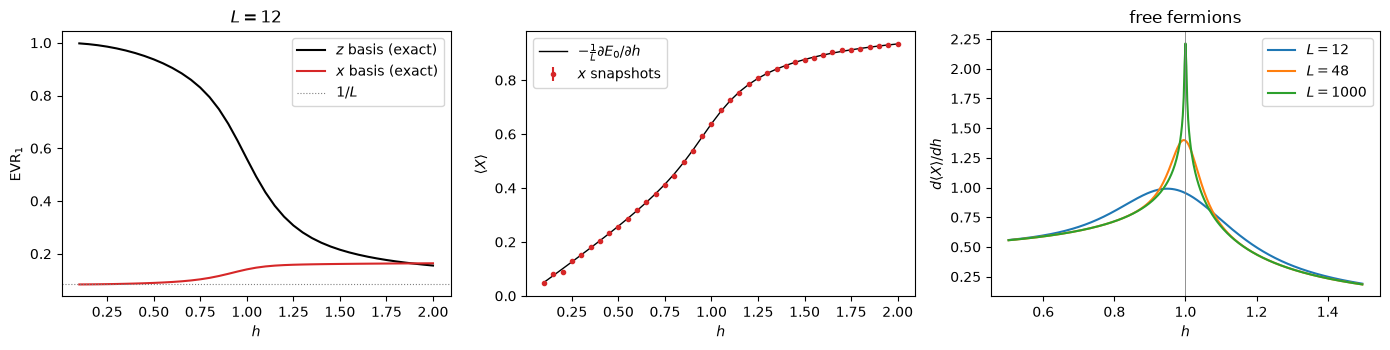

In [21]:
L, M = 12, 5000
rng = np.random.default_rng(11)
evr_x, mx_sn, mx_err = [], [], []
for h in H_GRID:
    px = tfim.probs(tfim.x_basis(gs(L, h)))
    lam = tfim.pca_cov(tfim.exact_cov(px))[0]
    evr_x.append(lam[0] / lam.sum())
    Xx = tfim.snapshots(tfim.x_basis(gs(L, h)), M, rng)
    mx_sn.append(Xx.mean()); mx_err.append(Xx.mean(1).std() / np.sqrt(M))
evr_x, mx_sn, mx_err = map(np.array, (evr_x, mx_sn, mx_err))
mx_hf = np.array([tfim.free_fermion_x(L, h) for h in H_GRID])
sel = H_GRID >= 0.3
print(f"x basis, L={L}: exact EVR1 between {evr_x[sel].min():.3f} and {evr_x[sel].max():.3f} for h in [0.3, 2]"
      f"  (1/L = {1 / L:.3f})")
print(f"<X> at h=1: snapshots {mx_sn[H_GRID == 1.0][0]:.4f} +- {mx_err[H_GRID == 1.0][0]:.4f}, "
      f"Hellmann-Feynman {tfim.free_fermion_x(L, 1.0):.4f}")
z = (mx_sn - mx_hf) / mx_err
check('x basis: no dominant component (exact EVR1 < 0.2 for all h in [0.3, 2])', evr_x[sel].max() < 0.2)
check('x basis: <X> from snapshots = Hellmann-Feynman within MC error',
      np.mean(z**2) < 1 + 3 * np.sqrt(2 / len(z)) and np.abs(z).max() < 4,
      f'chi2/dof = {np.mean(z**2):.2f} over {len(z)} fields')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(H_GRID, SW[12]['m2'], 'k-', label='$z$ basis (exact)')
ax[0].plot(H_GRID, evr_x, 'C3-', label='$x$ basis (exact)')
ax[0].axhline(1 / L, color='gray', ls=':', lw=0.8, label='$1/L$')
ax[0].set_xlabel('$h$'); ax[0].set_ylabel('EVR$_1$'); ax[0].legend(); ax[0].set_title(f'$L={L}$')
ax[1].errorbar(H_GRID, mx_sn, mx_err, fmt='o', ms=3, color='C3', label='$x$ snapshots')
ax[1].plot(H_GRID, mx_hf, 'k-', lw=1, label=r'$-\frac{1}{L}\partial E_0/\partial h$')
ax[1].set_xlabel('$h$'); ax[1].set_ylabel(r'$\langle X\rangle$'); ax[1].legend()
hh = np.linspace(0.5, 1.5, 401)
for Lb in [12, 48, 1000]:
    mx = np.array([tfim.free_fermion_x(Lb, x) for x in hh])
    ax[2].plot(hh[1:-1], (mx[2:] - mx[:-2]) / (hh[2] - hh[0]), label=f'$L={Lb}$')
ax[2].axvline(1, color='gray', lw=0.6)
ax[2].set_xlabel('$h$'); ax[2].set_ylabel(r'$d\langle X\rangle/dh$'); ax[2].legend(); ax[2].set_title('free fermions')
plt.tight_layout(); plt.show()

Held. In the $x$ basis PCA finds nothing dominant: EVR₁ stays below 0.17 at every $h$, at most twice the $1/L$ of
uncorrelated noise, with only a gentle step through the transition. The
transition is plainly there in $\langle X\rangle$, measured to $\pm0.004$ from the same snapshots, and its slope
develops a peak at $h_c$ that sharpens with $L$ (a log divergence: the analog of the specific heat). But that is a
*mean*, and PCA starts by subtracting the mean. What PCA can find depends on the measurement basis, and the
experimenter chooses the basis.

### Verdict on the predictions

1. **Antiferromagnet: held exactly.** PC1 is the staggered vector and every number equals the ferromagnet's,
   as the sublattice rotation requires.
2. **ANNNI: held.** A degenerate pair at $k=\pi/2$ carries the variance, split only by shot noise. The $(\kappa,h)$
   map adds what was not predicted: incommensurate peaks ($\pi/6$, $\pi/3$) near and above $\kappa=1/2$, mostly
   where no mode dominates, plus a multiphase point at $\kappa=1/2$ where neither ordered mode wins.
3. **Readout error: held, with a twist in the sign.** The covariance scales as predicted and EVR₁ corrects
   cleanly. The Binder crossing moves *toward* $h_c$, which is the dangerous direction: uncorrected data look
   better and extrapolate past $h_c$. Inverting the readout kernel on the $m$ histogram fixes it.
4. **Wrong basis: held.** No dominant component at any $h$; the transition lives in a mean that PCA discards.

## Summary of checks

In [22]:
for name, ok in CHECKS: print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} passed")

PASS  E0 from ED matches free fermions
PASS  free-fermion E0 at h=1 equals -2/sin(pi/2L)
PASS  reference energies (12, 1) and (8, 0.5)
PASS  raw eigsh at L=12, h=0.05 falls into the trap
PASS  <P> = 1 after projection at L=12, h=0.05
PASS  projected E0 still matches free fermions at h=0.05
PASS  exact <m^2> at L=12 matches the brief
PASS  sum_r G(r) = L <m^2>
PASS  EVR1 = exact <m^2> within Monte Carlo error over the whole sweep
PASS  PC1 is the uniform vector for h <= 1.2 at every L
PASS  PC1 histograms match the exact P(m) (Pearson chi^2)
PASS  PCA of the exact covariance = exact S(k), sorted
PASS  snapshot S(k) = exact S(k) within Monte Carlo error
PASS  PC1 is k=0 and PC2, PC3 are the k = +-2pi/L pair
PASS  Gaussian surrogate has the same S(k), i.e. the same PCA
PASS  ... but a completely different Binder cumulant
PASS  exact Binder crossings match the brief
PASS  extrapolated h_c = 1 to within 1e-3
PASS  Binder from PC1 projections = Binder from the snapshot mean
PASS  exact cross